# Simulación de Demanda y Valor Subjetivo del Tiempo (VST) - Tren Rápido Tarragona - Valencia (ETV)

Simulación de elección modal (método pivote SP-RP) con 3 modos actuales (Auto, Bus, Tren) y el tren rápido como alternativa pivote. El VST se estima mediante simulación Monte Carlo.

**Cambios respecto a la versión anterior**
- La estimación SP usa un **logit binario** (`sm.Logit`) en lugar de MCO. Así los coeficientes quedan en escala de utilidad y pueden reutilizarse para predecir.
- El tren rápido tiene una **constante modal propia** (`ascTR = -1.07`). Recoge lo que no captan tiempo y precio: acceso a la estación, frecuencia, inercia hacia el modo actual... Está calibrada para que la cuota del tren rápido ronde el 17 % que daba la versión anterior.
- La constante estimada se asigna al tren rápido, no a la alternativa actual.
- La partición modal SP se calcula con probabilidades logit en **cada réplica** y después se promedia.
- El código está vectorizado, los tiempos se truncan para que no salgan negativos y las etiquetas se redondean.

## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

rng = np.random.default_rng(42)  # semilla para reproducibilidad

## 2. Parámetros

In [2]:
a = 1500         # personas encuestadas
r = 100          # réplicas Monte Carlo
VSTi = 0.20      # VST generador (€/min)
alpha_i = -0.1355            # utilidad marginal del ingreso (coef. del precio)
beta_i = VSTi * alpha_i      # coeficiente del tiempo
ascTR = -1.07    # constante modal del tren rápido en la SP

modos = ['Auto', 'Bus', 'Tren']
precio_rango = [            # precio RP uniforme (mín, máx), €
    (20, 38),  # Auto,
    (8, 23),  # Bus,
    (15, 34),  # Tren
]
tiempo_dist = [             # tiempo RP normal (media, desv. típ.), min
    (90, 15),  # Auto,
    (100, 25),  # Bus,
    (77, 22),  # Tren
]
cteModalRP = np.array([0.0, -4.0, -2.25])   # constantes RP
tasa = np.array([0.5, 0.6, 0.56])        # recargo de precio = reducción de tiempo, según modo actual
t_min = 10.0                         # tiempo mínimo (min) para truncar la normal

print(f"ASC tren rápido equivale a {ascTR/alpha_i:.2f} € por viaje")

ASC tren rápido equivale a 7.90 € por viaje


## 3. Funciones de simulación y estimación

In [3]:
J = len(modos)

def gumbel(size):
    return -np.log(-np.log(rng.uniform(size=size)))

def simular_replica():
    # --- Datos RP (preferencias reveladas) ---
    precioRP = np.column_stack([rng.uniform(lo, hi, a) for lo, hi in precio_rango])
    tiempoRP = np.column_stack([rng.normal(mu, sd, a) for mu, sd in tiempo_dist])
    tiempoRP = np.maximum(tiempoRP, t_min)

    URP = cteModalRP + beta_i * tiempoRP + alpha_i * precioRP + gumbel((a, J))
    yRP = URP.argmax(axis=1)                 # índice del modo elegido
    idx = np.arange(a)

    # --- Datos SP pivotados sobre el modo elegido ---
    precio = np.column_stack([precioRP[idx, yRP], precioRP[idx, yRP] * (1 + tasa[yRP])])
    tiempo = np.column_stack([tiempoRP[idx, yRP], tiempoRP[idx, yRP] * (1 - tasa[yRP])])

    U = np.column_stack([beta_i * tiempo[:, 0] + alpha_i * precio[:, 0],
                         ascTR + beta_i * tiempo[:, 1] + alpha_i * precio[:, 1]]) + gumbel((a, 2))
    yTR = (U.argmax(axis=1) == 1).astype(int)  # 1 si elige tren rápido

    return yRP, precio, tiempo, yTR

def estimar_logit(precio, tiempo, yTR):
    # Diferencias tren rápido - modo actual; la constante es la del tren rápido
    X = np.column_stack([np.ones(len(yTR)),
                         tiempo[:, 1] - tiempo[:, 0],
                         precio[:, 1] - precio[:, 0]])
    res = sm.Logit(yTR, X).fit(disp=0)
    return res.params  # [ASC_TR, b_tiempo, b_precio]

def particion(yRP, precio, tiempo, coefs):
    asc, bt, bp = coefs
    dV = asc + bt * (tiempo[:, 1] - tiempo[:, 0]) + bp * (precio[:, 1] - precio[:, 0])
    pTR = 1 / (1 + np.exp(-dV))                       # probabilidad logit de pasarse al TR
    rp = np.array([np.mean(yRP == k) for k in range(J)])
    cambio = np.array([pTR[yRP == k].mean() if np.any(yRP == k) else np.nan for k in range(J)])
    sp = np.append(rp * (1 - np.nan_to_num(cambio)), np.mean(pTR))   # modos actuales + tren rápido
    return rp, cambio, sp

## 4. Bucle Monte Carlo

In [4]:
res_coefs, res_rp, res_cambio, res_sp, res_obs = [], [], [], [], []

for f in range(r):
    yRP, precio, tiempo, yTR = simular_replica()
    coefs = estimar_logit(precio, tiempo, yTR)
    rp, cambio, sp = particion(yRP, precio, tiempo, coefs)
    res_coefs.append(coefs); res_rp.append(rp); res_cambio.append(cambio)
    res_sp.append(sp); res_obs.append(yTR.mean())

coefs = pd.DataFrame(res_coefs, columns=["ASC_TR", "b_tiempo", "b_precio"])
coefs["VST"] = coefs["b_tiempo"] / coefs["b_precio"]
VSTT = coefs["VST"].to_numpy()

print("Parámetros estimados (media de las réplicas) vs verdaderos:")
print(pd.DataFrame({"estimado": coefs.mean(), "desv. típ.": coefs.std(),
                    "verdadero": [ascTR, beta_i, alpha_i, VSTi]}).round(4))

Parámetros estimados (media de las réplicas) vs verdaderos:
          estimado  desv. típ.  verdadero
ASC_TR     -1.1021      0.4236    -1.0700
b_tiempo   -0.0276      0.0065    -0.0271
b_precio   -0.1352      0.0233    -0.1355
VST         0.2103      0.0645     0.2000


## 5. Partición modal RP y SP

In [5]:
ParticionModalRP = np.mean(res_rp, axis=0)
ParticionModalSP = np.mean(res_sp, axis=0)
CambioATR = np.nanmean(res_cambio, axis=0)

EtiquetasRP = modos
EtiquetasSP = modos + ["Tren Rápido"]

tabla = pd.DataFrame({"Cuota RP": ParticionModalRP,
                      "% que pasa al TR": CambioATR,
                      "Cuota SP": ParticionModalSP[:J]}, index=modos)
print(tabla.round(3))
print(f"\nCuota SP del tren rápido (predicha):  {ParticionModalSP[J]:.3f}")
print(f"Cuota SP del tren rápido (observada): {np.mean(res_obs):.3f}")

      Cuota RP  % que pasa al TR  Cuota SP
Auto     0.668             0.152     0.567
Bus      0.086             0.328     0.058
Tren     0.246             0.166     0.205

Cuota SP del tren rápido (predicha):  0.171
Cuota SP del tren rápido (observada): 0.171


## 6. Gráficos

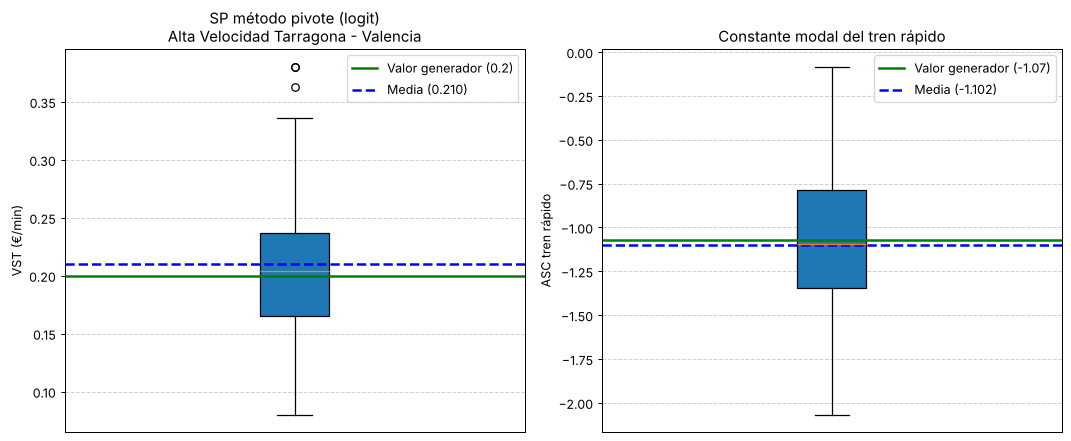

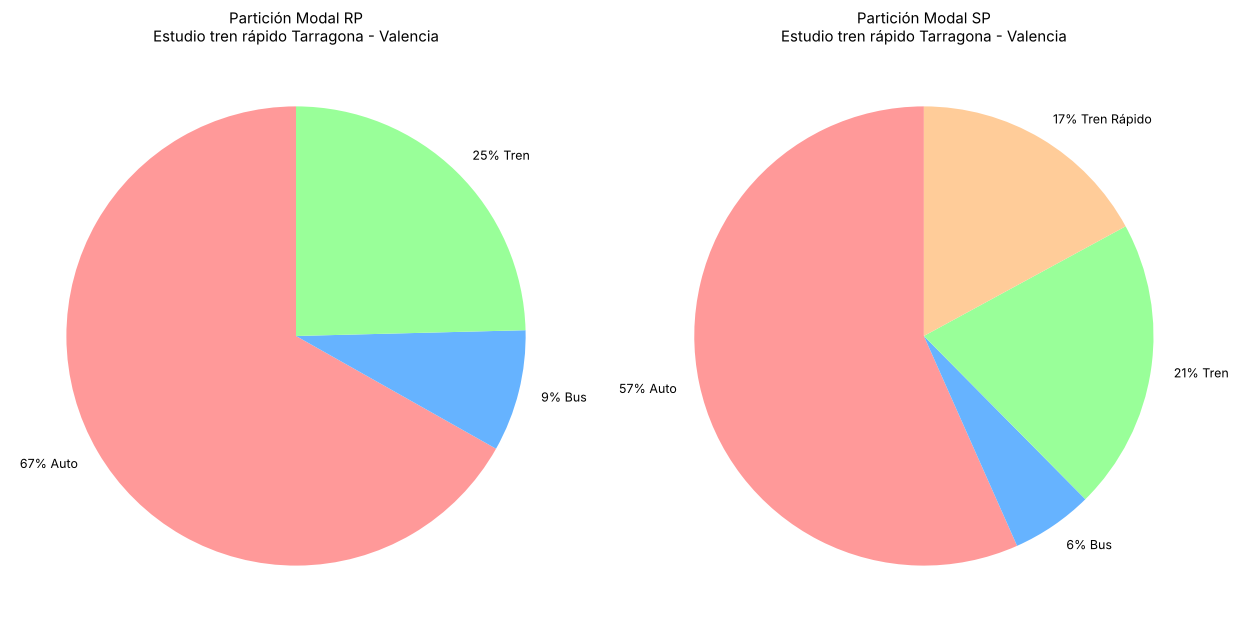

In [6]:
titulo = "Tarragona - Valencia"
colores = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, real, nombre in [(axes[0], "VST", VSTi, "VST (€/min)"),
                              (axes[1], "ASC_TR", ascTR, "ASC tren rápido")]:
    ax.boxplot(coefs[col], patch_artist=True)
    ax.axhline(real, color="green", lw=2, label=f"Valor generador ({real})")
    ax.axhline(coefs[col].mean(), color="blue", ls="--", lw=2,
               label=f"Media ({coefs[col].mean():.3f})")
    ax.set_ylabel(nombre); ax.set_xticks([]); ax.legend(); ax.grid(True, ls="--", alpha=0.6)
axes[0].set_title(f"SP método pivote (logit)\nAlta Velocidad {titulo}")
axes[1].set_title("Constante modal del tren rápido")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].pie(ParticionModalRP, labels=[f"{p*100:.0f}% {e}" for p, e in zip(ParticionModalRP, EtiquetasRP)],
            startangle=90, colors=colores[:J])
axes[0].set_title(f"Partición Modal RP\nEstudio tren rápido {titulo}")
axes[1].pie(ParticionModalSP, labels=[f"{p*100:.0f}% {e}" for p, e in zip(ParticionModalSP, EtiquetasSP)],
            startangle=90, colors=colores)
axes[1].set_title(f"Partición Modal SP\nEstudio tren rápido {titulo}")
plt.tight_layout(); plt.show()